In [48]:
%reset
%matplotlib inline
low_memory=False
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import silhouette_score
import seaborn as sns;
from scipy.stats import mode
import scipy.cluster.hierarchy  as shc
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans

## 8.1 Introduction & Motivation

Just like in the previous chapter, we're analyzing our data to answer a fundamental question: within the given data, are there any **groups** or **clusters** of datapoints that naturally belong together?

However, this time we'll explore **hierarchical clustering**, which takes a different approach:

**How it works:**
1. Start with each individual datapoint as its own cluster
2. Progressively merge the closest clusters together
3. Continue until only one cluster remains
4. Choose where to "cut" the hierarchy to get the optimal number of clusters

**Key advantage:** We can visualize the entire clustering process and decide on the optimal number of clusters after seeing the structure, rather than guessing beforehand.

## 8.2 Problem Setting

**Business Scenario:**

Consider an automobile manufacturer that has developed prototypes for a new vehicle. Before launching this new model, the manufacturer needs to understand the competitive landscape:

**Key Questions:**
* Which existing vehicles on the market most closely resemble our prototypes?
* What categories of vehicles currently exist in the market?
* Which category is our new model most similar to?
* Who will be our direct competitors?

**Our Approach:**

We'll use clustering techniques to identify distinct groups of vehicles based on their characteristics. This will:
1. Provide a clear overview of the current market structure
2. Help identify which segment our new model fits into
3. Reveal our direct competition
4. Inform strategic decisions about positioning and marketing

**Dataset:** We'll work with data on various cars, including specifications like engine size, fuel efficiency, dimensions, and pricing.

## 8.3 Model

First, let's have a look at the data.

In [49]:
df = pd.read_csv("/Users/mohammedsadmanuddin/data science fund/Hierarchical Clustering/Cars.csv")
df.head()

,manufact,model,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,lnsales,partition
0,Acura,Integra,16.919,16.360,0.0,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2.828,0.0
1,Acura,TL,39.384,19.875,0.0,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,3.673,0.0
2,Acura,RL,8.588,29.725,0.0,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2.150,0.0
3,Audi,A4,20.397,22.255,0.0,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,3.015,0.0
4,Audi,A6,18.780,23.555,0.0,33.95,2.8,200.0,108.7,76.1,192.0,3.561,18.5,22.0,2.933,0.0


##### Question 1: Create a correlation heatmap to explore the relationships between variables in the dataset.

**Instructions:**
* Plot a heatmap showing correlations between all numerical columns
* You'll encounter two columns that cannot be plotted (non-numerical)
* **Important:** Drop these two columns from the heatmap visualization only
* Do NOT drop them from your main dataframe - we'll need them later for labeling
* **Hint:** You can either use `.drop()` temporarily in the plotting command or store them in a separate dataframe

In [50]:
sep_columns = df[["manufact","model"]]
sep_columns.head()

,manufact,model
0,Acura,Integra
1,Acura,TL
2,Acura,RL
3,Audi,A4
4,Audi,A6


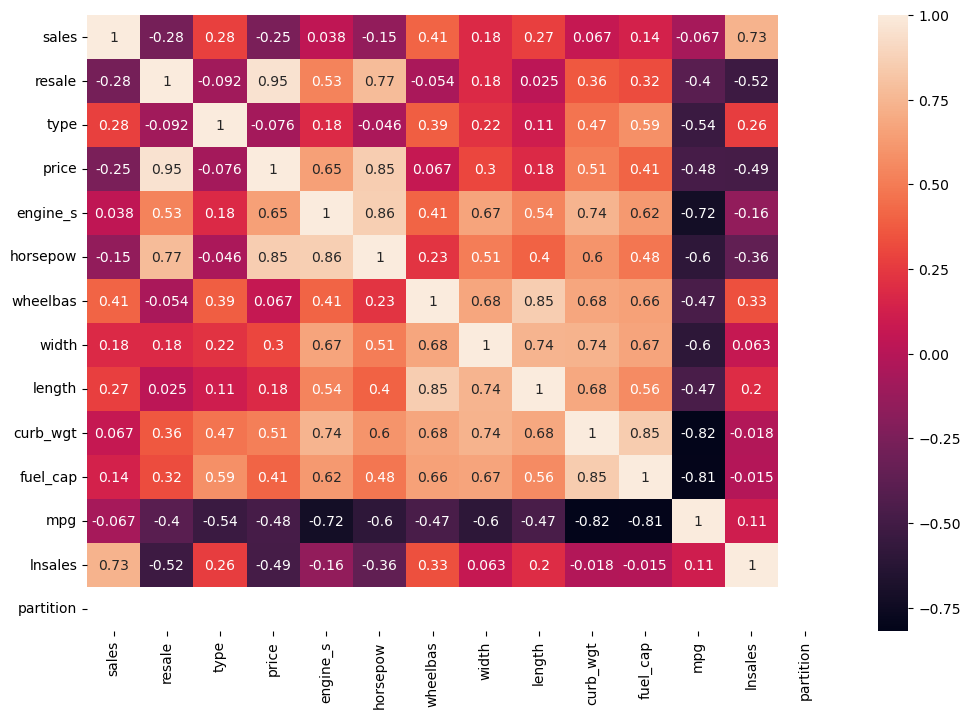

In [51]:
droped_columns=df.drop(columns=["manufact","model"])
corr = droped_columns.corr()
plt.figure(figsize=(12,8))
sns.heatmap(corr,annot=True)
plt.show()

##### Question 2: Investigate an unusual column in the correlation heatmap.

**Observation:** You'll notice one column that behaves differently than expected. 
* It shows no correlation with any other variables
* This is unusual - most car specifications are related to each other

**Your Tasks:**
1. Identify which column behaves unusually
2. Investigate why this is happening (examine the actual values)
3. Determine if this column provides any useful information
4. Decide whether to keep or drop it, and explain your reasoning

**Hint:** Use `.value_counts()` to see the distribution of values in suspicious columns.

- from the heatmap i can see partition column has no correlation to any other variables cuz in the column its only stated 0.It has no variation..so in that case it doesnt help anything for the clustering

**Your analysis here:**

In [52]:
df["partition"].value_counts()

partition
0.0    117
Name: count, dtype: int64

after couting the values of partition column it can be seen that its only 0 for the whole partition column..its better to drop cuz it has no linear correlation towards any of the variable

**Your conclusion and action:**

In [53]:
droped_columns = droped_columns.drop(columns="partition")
droped_columns.head()

,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,lnsales
0,16.919,16.360,0.0,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2.828
1,39.384,19.875,0.0,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,3.673
2,8.588,29.725,0.0,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2.150
3,20.397,22.255,0.0,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,3.015
4,18.780,23.555,0.0,33.95,2.8,200.0,108.7,76.1,192.0,3.561,18.5,22.0,2.933


In [54]:
droped_columns.head()

,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,lnsales
0,16.919,16.360,0.0,21.50,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2.828
1,39.384,19.875,0.0,28.40,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,3.673
2,8.588,29.725,0.0,42.00,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2.150
3,20.397,22.255,0.0,23.99,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,3.015
4,18.780,23.555,0.0,33.95,2.8,200.0,108.7,76.1,192.0,3.561,18.5,22.0,2.933


## 8.4 Model Evaluation

##### Question 3: Create a dendrogram to visualize the hierarchical clustering structure.

**Instructions:**
1. Create a dendrogram of the cars dataset
2. **Remember:** Exclude the two non-numerical columns ('manufact' and 'model') from the clustering
3. **However:** Use these columns to create meaningful labels for your dendrogram
4. **Hint:** Research the `leaf_label_func` parameter in the dendrogram function
5. Consider using horizontal orientation for better readability with many labels

**Goal:** Each car should be labeled with its manufacturer and model name (e.g., "[Toyota Camry]") so we can see which cars cluster together.

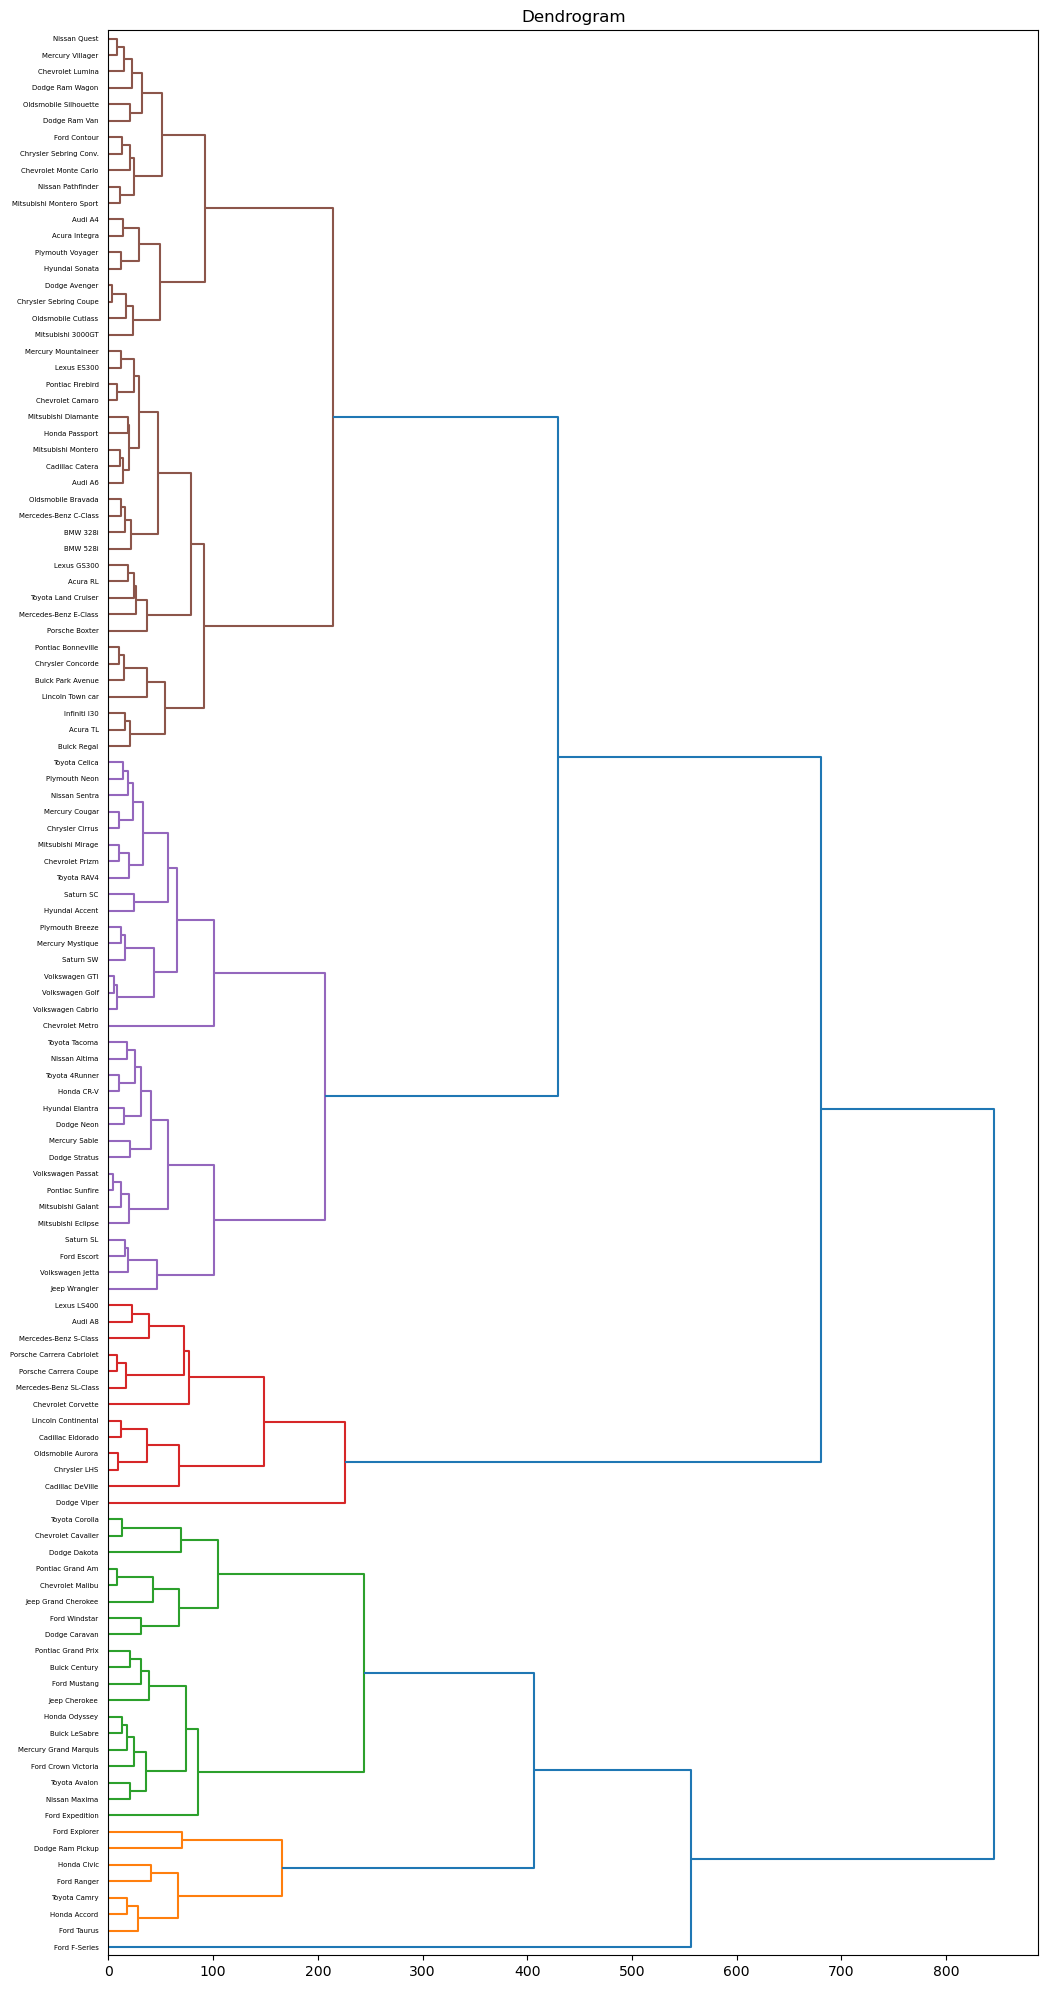

In [71]:
labels = df["manufact"]+" "+df["model"]
X = shc.linkage(droped_columns,method='ward')
plt.figure(figsize=(12,25))
dend = shc.dendrogram(X,color_threshold=280,labels=labels.to_list(),orientation="right")
plt.title("Dendrogram")
plt.show()

##### Question 4: Determine the optimal number of clusters by analyzing the dendrogram.

**Think about:**
* Hierarchical clustering merges clusters based on their distance/similarity
* We want to maximize separation between clusters (large distances)
* While minimizing the number of clusters (for interpretability)

**What to look for in the dendrogram:**
* Find where there's a long horizontal distance without any merges
* This indicates a natural "gap" between cluster levels
* The cutoff just before this gap gives you optimal clusters

**Your Task:**
1. Examine the dendrogram carefully
2. Identify where you would draw the cutoff line
3. Count how many clusters this would create
4. Explain your reasoning: Why is this number optimal?

**my analysis**
- accroding to the dendrogram i can see there are 4 major big cluster at 450,560,690,880..but my decision is 2 cluster cuz at 420 and two lower group merge...and then at 680 2 major group merge...My decision is to choose 2 clusters because after drawing the cutoff line at 600, only two major groups remain. These two groups merge at around 850. Therefore, I think 2 is the optimal number of clusters based on the dendrogram.

##### Question 5: Use the elbow method to mathematically determine the optimal number of clusters.

**Instructions:**
1. Create an elbow plot using the linkage criterion
2. Identify where the "elbow" (bend) occurs in the graph
3. Compare this result with your visual estimate from the dendrogram

**Questions to answer:**
* What number of clusters does the elbow method suggest?
* Does this match your estimate from Question 4?
* If there's a discrepancy, which method do you trust more and why?

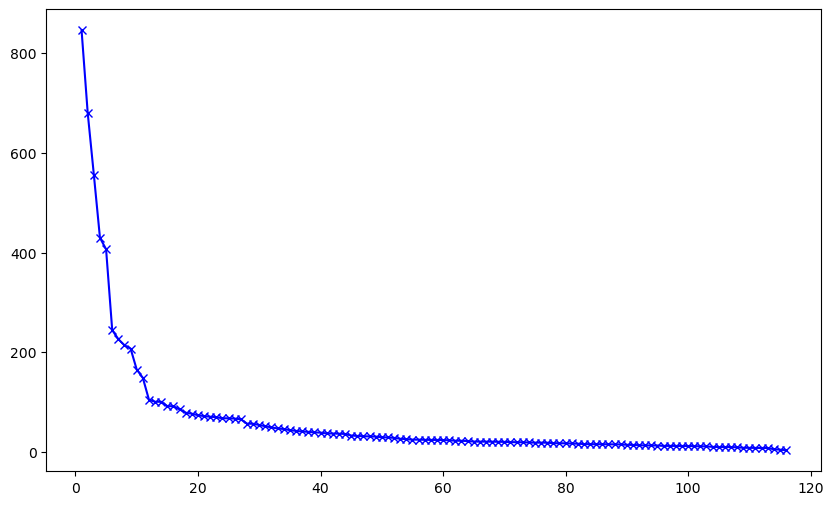

In [70]:
A = X[:, 2] #since linkage function stores the distances in 3rd column
plt.figure(figsize=(10, 6))
plt.plot(range(len(A), 0, -1), A,"bx-")
plt.show()

**Your analysis here:**
- accroding to the elbow method the optimal cluster is 12...the graphs shows from 12th cluster the curve start becoming more flaten...but the dendrogram shows how the optimal cluster is 2.
- i will take 2 cuz the dendrogram shows two major merge after the cutoff distance of 600.

##### Question 6: Visualize the clusters by drawing a cutoff line on the dendrogram.

**Tasks:**
1. Recreate the dendrogram from Question 3
2. Add a horizontal cutoff line showing where we divide into 6 clusters
3. Analyze the resulting groups

**Analysis Questions:**
* Do the cars in each cluster make intuitive sense?
* Are the clusters balanced (similar sizes) or unbalanced?
* If unbalanced, what might explain this?
* Can you identify the "type" of each cluster (e.g., sports cars, family cars, trucks)?

**Hint:** Use `plt.axvline()` to draw a vertical line (since orientation is 'right') at the appropriate distance.

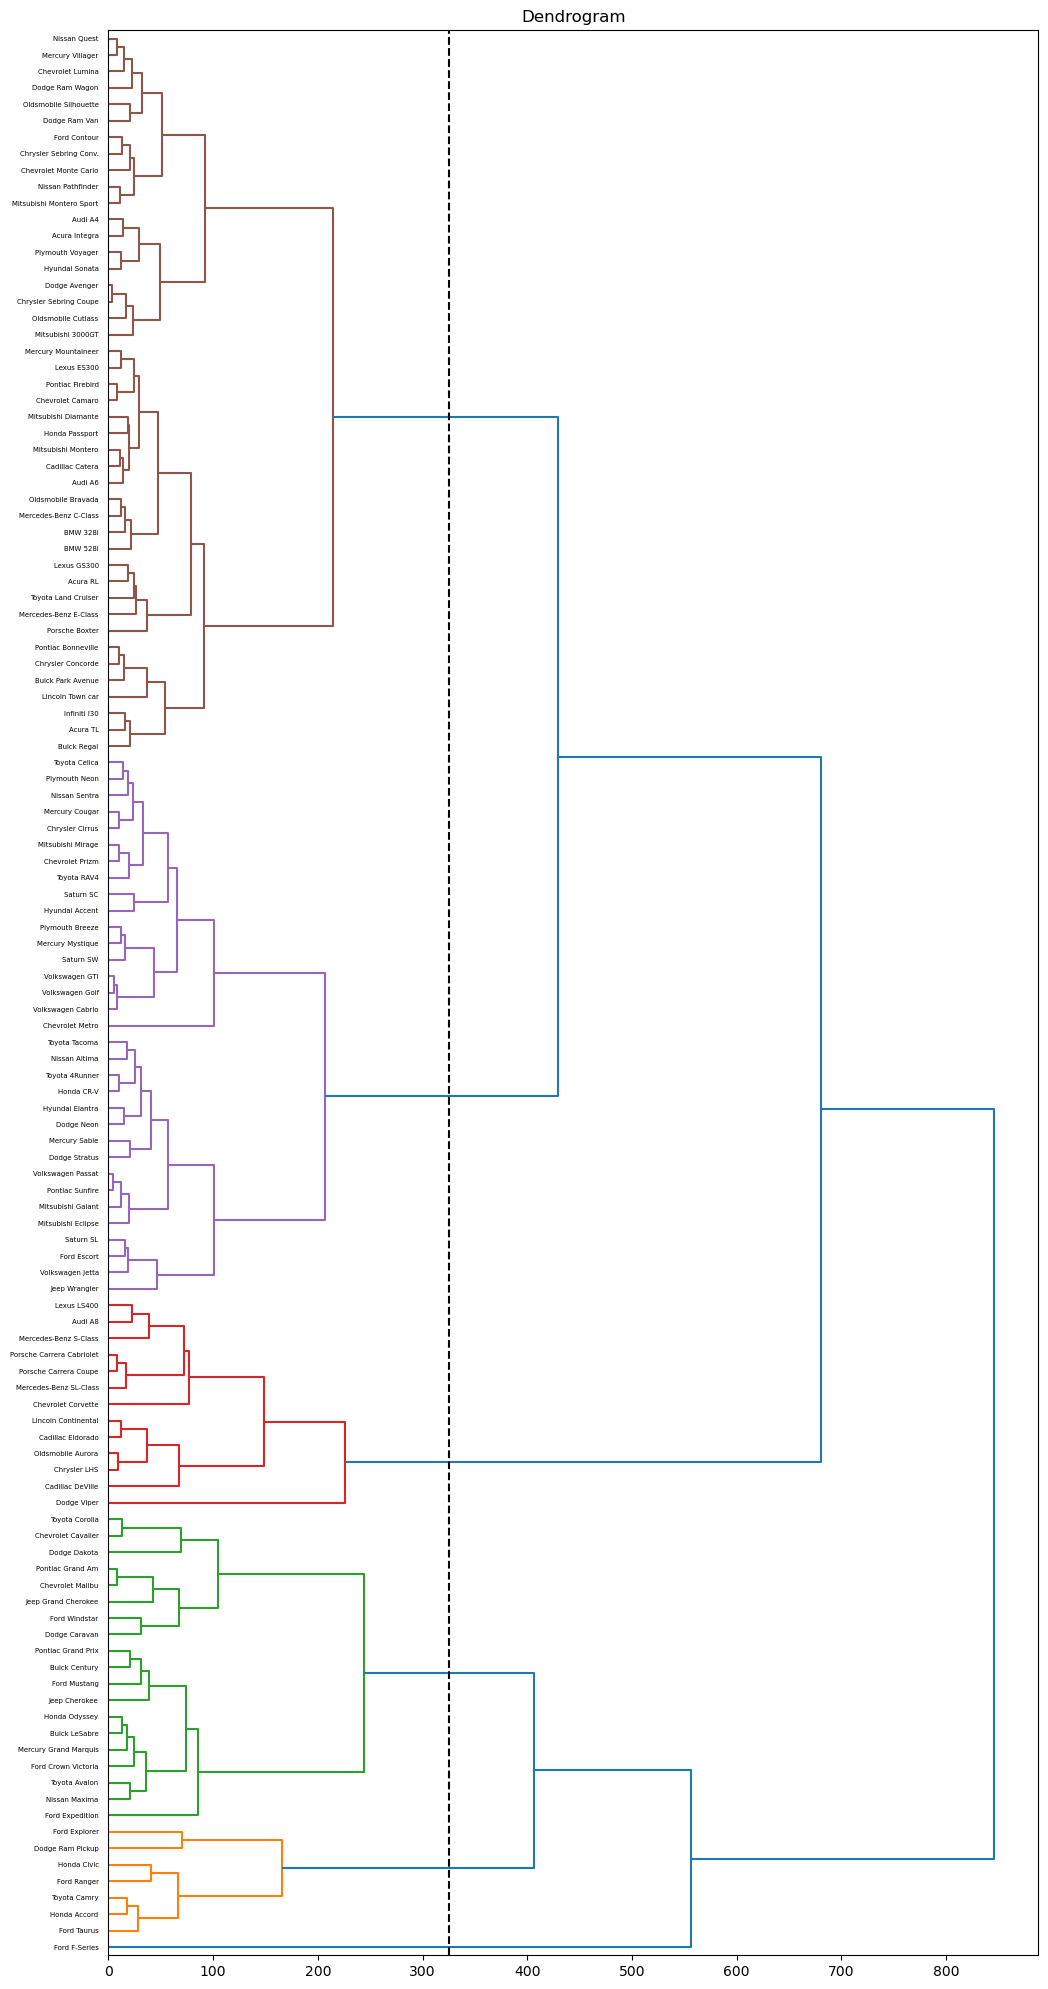

In [76]:
cut = (X[-6,2]+X[-5,2])/2
plt.figure(figsize=(12,25))
dend = shc.dendrogram(X,color_threshold=280,labels=labels.to_list(),orientation="right")
plt.axvline(x=cut,color='Black',linestyle='--')
plt.title("Dendrogram")
plt.show()

**Your analysis here:**

1. **Cluster Quality:**
   * Describe which types of cars are grouped together
      - from the cluster i can see that luxary cars are in one group,big cars are in another group like suv or truck..and the other group is normal cars or everyday car

2. **Cluster Balance:**
   * Are clusters similar in size or very different?
      - nope...some groups has a lot of car...some doesnt
   * What does this tell us about the data?
      - itt say each car act differently with their own specification

3. **Business Interpretation:**
   * What vehicle categories have you identified?
      - a lot of categories
   * How could a manufacturer use this information?

## 8.4 Exercises

##### Question 7: Consider the cars dataset. Which clustering method would you prefer? Why?

**Your comparative analysis here:**

Compare hierarchical clustering vs. k-Means for this dataset:

**Hierarchical Clustering Advantages:**

    - The hierarchical clustering helps us to identify the grouping of cars by using the dendrogram
    - we dont need to specify number of clusters before the heirarchy
    
**k-Means Advantages:**
    
    - i think for larger dataset k means is important...we can also use the elbow method to get the optimal k

**Your Recommendation:**

    - for this dataset i would choose hierarchical clustering cuz the dendrogram helps us to identify the cars visually

##### Question 8: For comparison, determine the optimal k for k-Means clustering.

**Task:** Create an elbow plot for k-Means to find the optimal number of clusters.

**Purpose:** This allows us to compare whether k-Means and hierarchical clustering suggest the same number of clusters for this dataset.

**Question:** Do the two methods agree on the optimal k? If they differ, why might that be?

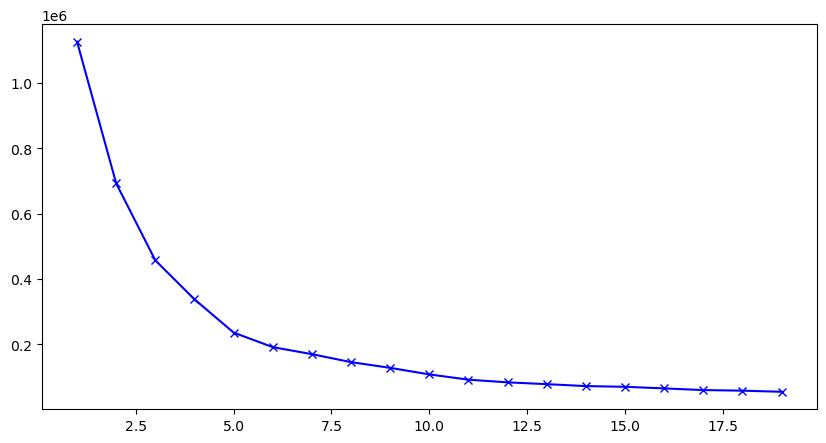

In [78]:
inertias_blobs = []
k_blobs=range(1,20)
for k in k_blobs:
    model=KMeans(n_clusters=k,n_init=10,random_state=0)
    model.fit(droped_columns)
    inertias_blobs.append(model.inertia_)
plt.figure(figsize=(10,5))
plt.plot(k_blobs,inertias_blobs,'bx-')
plt.show()

**Your comparison analysis here:**

i can see the elbow method of our kmeans model suggests the optimal k is 5...but from hierarchical clustering from the dendrogram i choosed 2 as optimal k...its maybe because of their methods of choosing it...kmeans choose the grps by the distance of their each centroids where hierarchical clustering uses ward to grp the cars